In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import sys
import os

# Add the parent directory to sys.path
current_dir = os.path.dirname(os.getcwd())
three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..'))
sys.path.append(three_dirs_up)

import matplotlib.gridspec as gridspec

#plt.style.use('ggplot')
# plt.style.use('seaborn-v0_8-ticks')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])

from trips.utilities.weights import smoothed_holder_weights


from msolver import IASGKS, MMGKS, VanillaGKS
from fsolver import IASFGK, MMFGK # VanillaFK
from pgkbsolver import MMGKB, IASGKB

# Setup toy problem

In [2]:
n = 1000
ground_truth = 5*np.ones(n)
ground_truth[:250] = 3
ground_truth[250:400] = 6
ground_truth[400:625] = 1
ground_truth[625:825] = 3
ground_truth[825:] = 5
grid = np.arange(n)

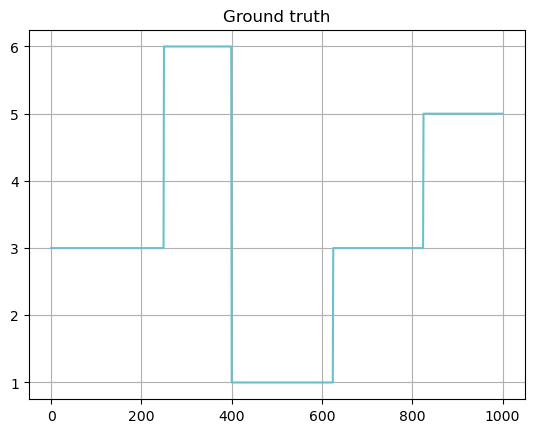

In [3]:
plt.plot(ground_truth)
plt.title("Ground truth")
plt.grid()
plt.show()

In [4]:
# Black box operator for DCT
from jlinops import _CustomLinearOperator

class DCT1D(_CustomLinearOperator):
    """Implements a 1D dct
    """

    def __init__(self, n, type=2, norm="ortho", device="cpu"):
        
        self.type = type
        self.n_size = n
        self.norm = norm


        def _matvec(x):
            return dct(np.squeeze(x), type=self.type, norm=self.norm)
        
        def _rmatvec(x):
            return idct(np.squeeze(x), type=self.type, norm=self.norm)
        
        super().__init__( (n,n), _matvec, _rmatvec, device=device, dtype=None)


In [5]:
F = DCT1D(n)
F_explicit = jlinops.black_box_to_dense(F)

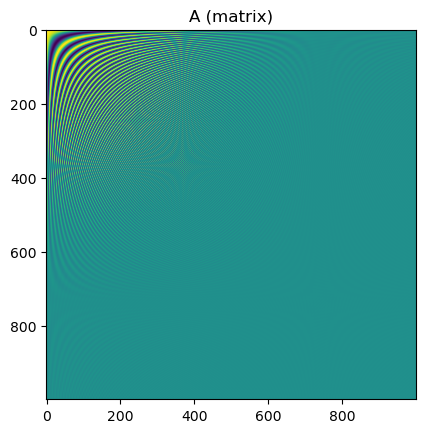

In [6]:
plt.imshow(F_explicit)
plt.title("A (matrix)")
plt.show()

In [7]:
# # Random undersampling
# np.random.seed(0)
# mask = np.random.binomial(1, 0.8, size=n)
# P = jlinops.Subsampling1DOperator(mask)

# Only first 100 components
mask = np.ones(n)
mask[50:] = 0.0
P = jlinops.Subsampling1DOperator(mask)

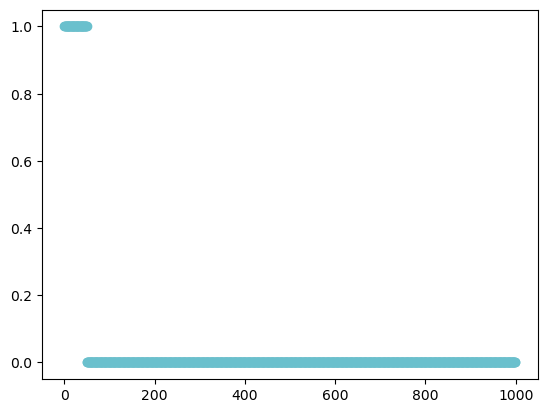

In [8]:
plt.scatter(grid, mask)
plt.show()

In [9]:
# Generate synthetic data
np.random.seed(0)
A = P @ F
b_true = A @ ground_truth
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_level_sigma = 0.03
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
#noise_sigma = 0.01*np.amax(b_true)
#noise_var = noise_sigma**2
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
b = b_true + noise_vec
#b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])

In [10]:
noise_var

0.2514573489857872

In [11]:
# # Inverse DCT reconstruction
# plt.plot(A.T @ b)
# plt.plot(ground_truth, color="k")
# plt.show()

In [12]:
# # # Other way of generating the data

# # Generate synthetic data
# np.random.seed(0)
# A = P @ F
# b_true = A @ ground_truth
# noise_sigma = 0.2
# b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])
# noise_var = noise_sigma**2

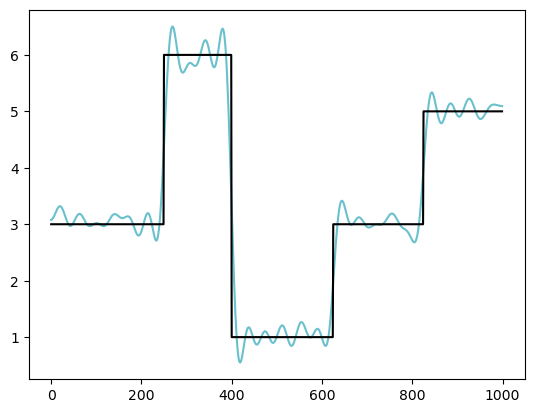

In [13]:
# Inverse DCT reconstruction
plt.plot(A.T @ b)
plt.plot(ground_truth, color="k")
plt.show()

# Setup prior

In [14]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator
Kmat = Kmat/np.linalg.norm(Kmat)

# Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="zero")
# L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator


# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

K = jlinops.MatrixLinearOperator(Kmat)
K

#err_norm_sq = len(b) # in expectation

# Build solvers

q = 1.0
epsilon = 1e-4
mmgks_weight_params = {
    "q": q,
    "epsilon": epsilon,
}

iasgks_weight_params = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}

gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

mmgks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
mmfk_solver = MMFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
mmgkb_solver = MMGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

iasgks_solver = IASGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
iasfk_solver = IASFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
iasgkb_solver = IASGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)


AK = A @ K.A
AKpinv = jlinops.QRPinvOperator(AK)
xker = K @ (AKpinv @ b)

# Run all methods

In [59]:
n_its = 200
method = "dp"

ksparsity = 15

vpdata = gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params={}, 
                                                 regparam_kwargs={"eta":1.01})
print("Finished L2 GKS (priorconditioned)")

vdata = gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params={}, ksparsity=ksparsity,
                                    regparam_kwargs={"eta":1.01},  xker=xker)
print("Finished L2 GKS (vanilla)")

mm_pdata = mmgks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params, 
                                                 regparam_kwargs={"eta":1.01})
print("Finished S-GKS (priorconditioned)")


mm_data = mmgks_solver.solve(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)
print("Finished S-GKS (vanilla)")

mm_resdata = mmgks_solver.solve(n_iter=800, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, ksparsity=4, weight_params=mmgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker, restart_dim=60)
print("Finished S-GKS (restarted)")


mm_recdata = mmgks_solver.solve(n_iter=800, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=30, max_dim=60, xker=xker, restart_dim=None)
print("Finished S-GKS (recycling)")


mm_fkdata = mmfk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished FK Solver")


mm_gkbdata = mmgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params, refresh_basis=True,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished P-GKB")




## Also do IAS weights

ias_pdata = iasgks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, 
                                                 regparam_kwargs={"eta":1.01})
print("Finished S-GKS (priorconditioned)")


ias_data = iasgks_solver.solve(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)
print("Finished S-GKS (vanilla)")

ias_resdata = iasgks_solver.solve(n_iter=800, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, ksparsity=4, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker, restart_dim=60)
print("Finished S-GKS (restarted)")


ias_recdata = iasgks_solver.solve(n_iter=800, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=30, max_dim=60, xker=xker, restart_dim=None)
print("Finished S-GKS (recycling)")


ias_fkdata = iasfk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished FK Solver")


ias_gkbdata = iasgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, refresh_basis=True,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished P-GKB")



1e-07


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/tests/1d_cosine/../../msolver.py:800: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-07
1e-07
1e-07
1e-07
1e-07
31.62319095539862
116.24592604025442
131.9758275702863
139.30801128708316
141.62733364738875
143.01885429086008
143.3788125638155
143.4830559244382
143.5076428188278
143.51449535809328
143.51610550832717
143.5163801700576
143.5164577106791
143.51647445330914
143.51647660475527
143.51647693212198
143.5164770082982
143.5164770162038
143.51647701729678
143.51647701743534
143.51647701744437
143.5164770174447
143.51647701744477
143.5164770174449
143.51647701744486
143.51647701744488
143.5164770174449
143.51647701744488
143.5164770174449
143.51647701744474
143.51647701744477
143.51647701744486
143.51647701744483
143.51647701744474
143.51647701744466
143.51647701744477
143.51647701744477
143.51647701744486
143.5164770174449
143.51647701744452
143.51647701744486
143.51647701744486
143.51647701744483
143.51647701744488
143.5164770174449
143.51647701744486
143.51647701744488
143.5164770174448
143.51647701744486
143.51647701744486
143.51647701744486
143.5164770174448

712.4352939343164
313.37688956665164
173.65850933017586
160.22316437180504
156.42683371661784
154.5182676308331
153.02692623933018
151.53095534516513
149.85582845753214
148.28508304070328
147.03265125815278
146.16390266639357
145.5579899324737
145.11634310699793
144.7776471164702
144.49582192950552
144.2765757634909
144.09680125755997
143.95377910532878
143.83566235329278
143.7421485449182
143.67958142370674
143.63150284563577
143.59602087803415
143.57101709999938
143.55184798233
143.53864453656294
143.52944053731824
143.5226257228036
143.51812172305557
143.5151546915997
143.51349734228555
143.51286739220728
143.51275201379985
143.51298594693645
143.51342217547386
143.51391147873576
143.51437853738582
143.51482640259647
143.51525087768073
143.51557453481388
143.51585608698917
143.51607582590736
143.51622167901527
143.5163353229858
143.51643068333658
143.51649608465053
143.51653867376675
143.51656341196082
143.51657662998304
143.5165808589555
143.51657785191722
143.51656911946577
143.51

1e-07
9.152249063987906
12.124848631952299
13.898700397613771
14.937625662829022
15.468317982564775
15.882136713248832
16.355915814083982
16.764000216033047
17.181340881511236
17.58926032865126
17.977569629078484
18.37157687065222
18.739434477200792
19.095178655020646
19.432599254313164
19.75227600499657
20.05134604876726
20.332771709634777
20.59396341563322
20.833913977382025
21.057134719132225
21.263447884726734
21.454404839766713
21.631885900381835
21.797142142315113
21.95104398280325
22.09494030629391
22.229770867184012
22.35637627547815
22.47552358160783
22.587908926243916
22.694115769918817
22.794658916189174
22.890027988705345
22.980622953627655
23.066805623122843
23.14889718944517
23.227193324652006
23.301946259557702
23.373393028494295
23.44174755659456
23.507200585951836
23.56992956910151
23.63009901386974
23.687860432556857
23.743349937837888
23.796699676567233
23.84802874071885
23.897448993769384
23.945064663328658
23.99097303773014
24.035263705668168
24.078021569089447
24.

...


generating basis...: 100%|██████████| 199/199 [00:00<00:00, 1717.25it/s]


1000000.0


generating basis...: 100%|██████████| 200/200 [00:00<00:00, 1712.03it/s]

1000000.0


Finished P-GKB


# Make plots

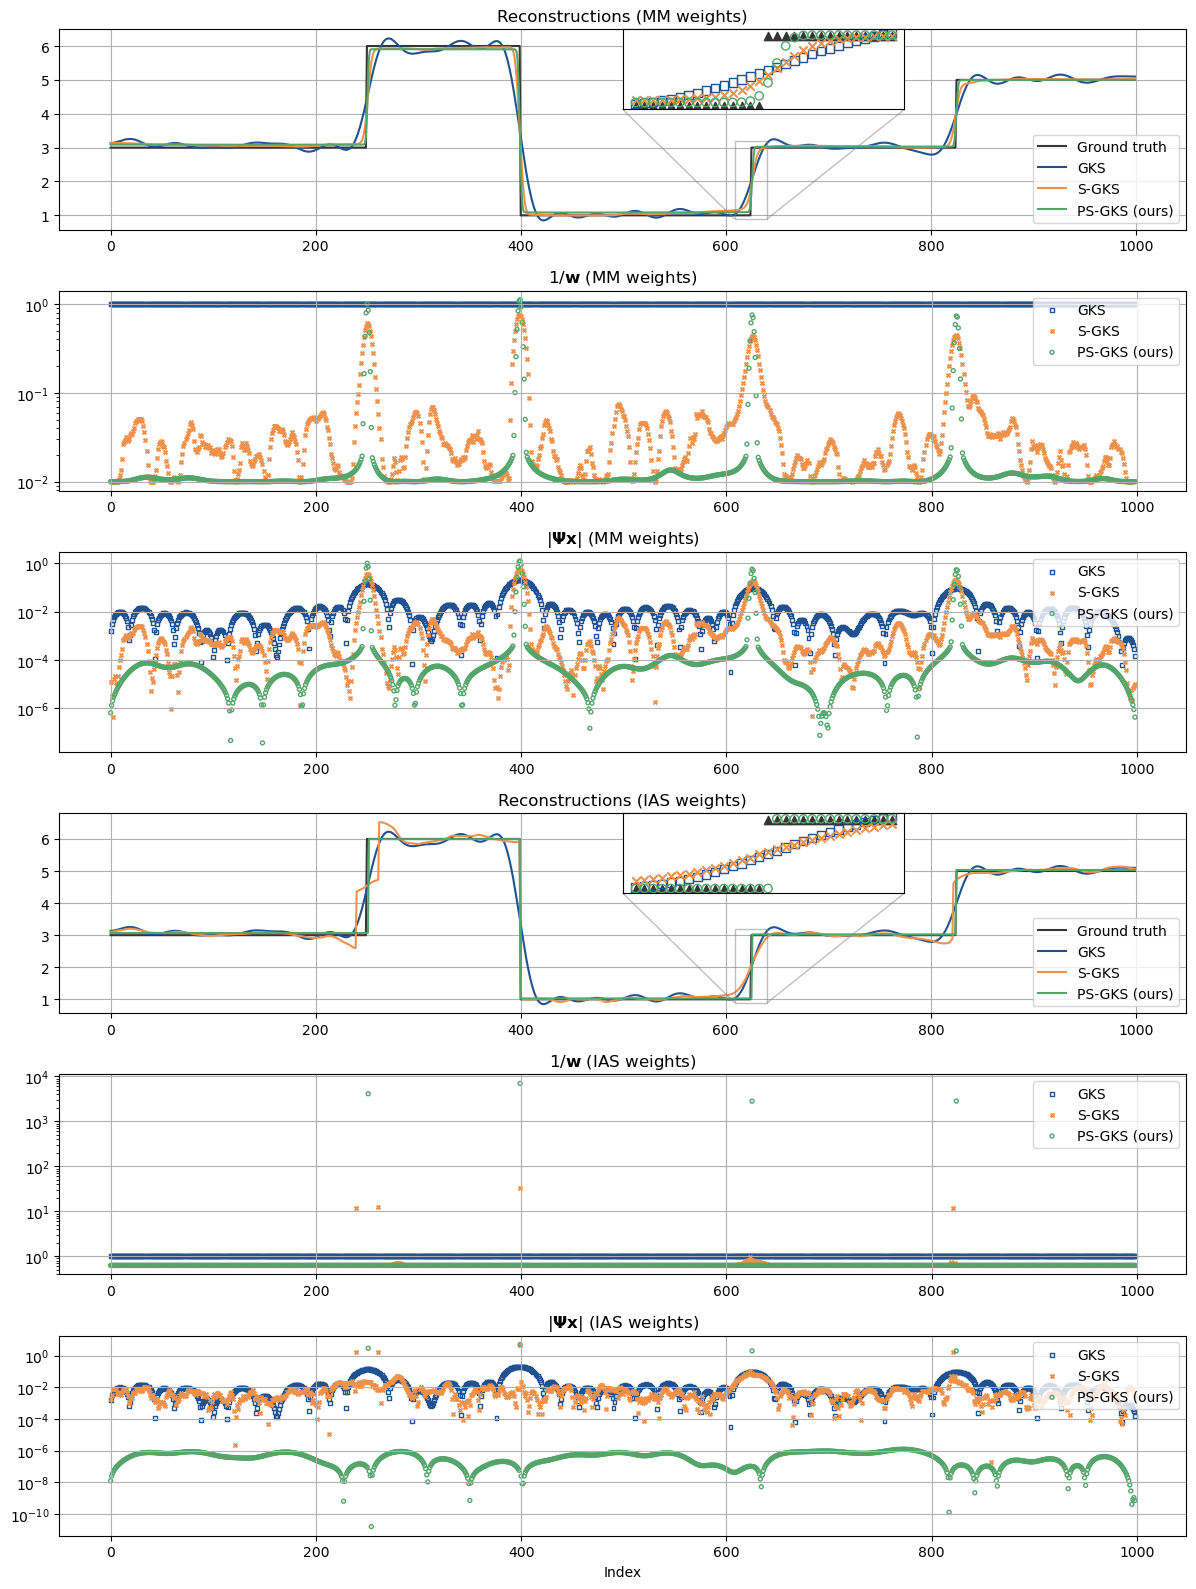

In [88]:
# Create a figure with a 2x3 grid
fig = plt.figure(figsize=(12, 2*8))
gs = gridspec.GridSpec(6, 1, figure=fig)

# Combine the first two subplots at positions (0,0) and (0,1)
ax1 = fig.add_subplot(gs[0])
ax1.plot([i for i in range(len(mm_data["x"]))], ground_truth, label="Ground truth", color="C9", alpha=1.0)
ax1.plot([i for i in range(len(mm_data["x"]))], vdata["x"], label="GKS", color="C3")
ax1.plot([i for i in range(len(mm_data["x"]))], mm_data["x"], label="S-GKS", color="C5")
ax1.plot([i for i in range(len(mm_data["x"]))], mm_pdata["x"], label="PS-GKS (ours)", color="C4")

inset_ax = ax1.inset_axes([0.5, 0.6, 0.25, 0.4])  # [left, bottom, width, height]
inset_ax.set_xticks([])
inset_ax.set_yticks([])
inset_low_coord = 610
inset_high_coord = 640
inset_ax.scatter([i for i in range(len(mm_data["x"]))][inset_low_coord:inset_high_coord], ground_truth[inset_low_coord:inset_high_coord], label="Ground truth", color="C9", alpha=1.0, marker="^")
inset_ax.scatter([i for i in range(len(mm_data["x"]))][inset_low_coord:inset_high_coord], vdata["x"][inset_low_coord:inset_high_coord], label="GKS", color="C3", marker="s", facecolors="none")
inset_ax.scatter([i for i in range(len(mm_data["x"]))][inset_low_coord:inset_high_coord], mm_data["x"][inset_low_coord:inset_high_coord], label="S-GKS", color="C5", marker="x")
inset_ax.scatter([i for i in range(len(mm_data["x"]))][inset_low_coord:inset_high_coord], mm_pdata["x"][inset_low_coord:inset_high_coord], label="PS-GKS (ours)", color="C4", marker="o", facecolors="none")
inset_ax.grid()

ax1.indicate_inset_zoom(inset_ax)
ax1.legend(loc="lower right")
ax1.set_title('Reconstructions (MM weights)')
ax1.grid()


ax2 = fig.add_subplot(gs[1])
ax2.scatter([i for i in range(len(mm_data["w"]))], 1.0/vdata['w'], label="GKS", color="C3", marker="s", s=8, facecolors="none")
ax2.scatter([i for i in range(len(mm_data["w"]))], 1.0/mm_data['w'], label="S-GKS", color="C5", marker="x", s=8)
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
ax2.scatter([i for i in range(len(mm_data["w"]))], 1.0/mm_pdata['w'], label="PS-GKS (ours)", color="C4", s=8, marker="o", facecolors="none")
#ax2.scatter([i for i in range(len(mm_data["w"]))], 1.0/mm_fkdata['w'], label="FGK", color="C6", s=8, marker=">", facecolors="none")
ax2.set_title("$1/\\mathbf{w}$ (MM weights)")
#ax2.set_xlabel("Index")
ax2.set_yscale("log")
ax2.legend(loc="upper right")
ax2.grid()




ax10 = fig.add_subplot(gs[2])
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
ax10.scatter([i for i in range(len(mm_data["w"]))], np.abs(L @ vdata['x']), label="GKS", color="C3", marker="s", s=8, facecolors="none")
ax10.scatter([i for i in range(len(mm_data["w"]))], np.abs(L @ mm_data['x']), label="S-GKS", color="C5", marker="x", s=8)
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ resdata['x']), label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ recdata['x']), label="S-GKS (recycling)", color="C1", ls=":")
ax10.scatter([i for i in range(len(mm_data["w"]))], np.abs(L @ mm_pdata['x']), label="PS-GKS (ours)", color="C4", s=8, marker="o", facecolors="none")
#ax10.scatter([i for i in range(len(mm_data["w"]))], np.abs(L @ mm_fkdata['x']), label="FGK", color="C6", s=8, marker=">", facecolors="none")
ax10.set_title("$| \\boldsymbol{\\Psi} \\mathbf{x} |$ (MM weights)")
# ax10.set_xlabel("Index")
ax10.set_yscale("log")
ax10.legend(loc="upper right")
ax10.grid()







# Combine the first two subplots at positions (0,0) and (0,1)
ax22 = fig.add_subplot(gs[3])
ax22.plot([i for i in range(len(mm_data["x"]))], ground_truth, label="Ground truth", color="C9", alpha=1.0)
ax22.plot([i for i in range(len(mm_data["x"]))], vdata["x"], label="GKS", color="C3")
ax22.plot([i for i in range(len(mm_data["x"]))], ias_data["x"], label="S-GKS", color="C5")
ax22.plot([i for i in range(len(mm_data["x"]))], ias_pdata["x"], label="PS-GKS (ours)", color="C4")

inset_ax = ax22.inset_axes([0.5, 0.6, 0.25, 0.4])  # [left, bottom, width, height]
inset_ax.set_xticks([])
inset_ax.set_yticks([])
inset_low_coord = 610
inset_high_coord = 640
inset_ax.scatter([i for i in range(len(mm_data["x"]))][inset_low_coord:inset_high_coord], ground_truth[inset_low_coord:inset_high_coord], label="Ground truth", color="C9", alpha=1.0, marker="^")
inset_ax.scatter([i for i in range(len(mm_data["x"]))][inset_low_coord:inset_high_coord], vdata["x"][inset_low_coord:inset_high_coord], label="GKS", color="C3", marker="s", facecolors="none")
inset_ax.scatter([i for i in range(len(mm_data["x"]))][inset_low_coord:inset_high_coord], ias_data["x"][inset_low_coord:inset_high_coord], label="S-GKS", color="C5", marker="x")
inset_ax.scatter([i for i in range(len(mm_data["x"]))][inset_low_coord:inset_high_coord], ias_pdata["x"][inset_low_coord:inset_high_coord], label="PS-GKS", color="C4", marker="o", facecolors="none")
inset_ax.grid()

ax22.indicate_inset_zoom(inset_ax)
ax22.legend(loc="lower right")
ax22.set_title('Reconstructions (IAS weights)')
ax22.grid()


ax33 = fig.add_subplot(gs[4])
ax33.scatter([i for i in range(len(mm_data["w"]))], 1.0/vdata['w'], label="GKS", color="C3", marker="s", s=8, facecolors="none")
ax33.scatter([i for i in range(len(mm_data["w"]))], 1.0/ias_data['w'], label="S-GKS", color="C5", marker="x", s=8)
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
ax33.scatter([i for i in range(len(mm_data["w"]))], 1.0/ias_pdata['w'], label="PS-GKS (ours)", color="C4", s=8, marker="o", facecolors="none")
#ax33.scatter([i for i in range(len(mm_data["w"]))], 1.0/ias_fkdata['w'], label="FGK", color="C6", s=8, marker=">", facecolors="none")
ax33.set_title("$1/\\mathbf{w}$ (IAS weights)")
#ax2.set_xlabel("Index")
ax33.set_yscale("log")
ax33.legend(loc="upper right")
ax33.grid()




ax44 = fig.add_subplot(gs[5])
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
ax44.scatter([i for i in range(len(ias_data["w"]))], np.abs(L @ vdata['x']), label="GKS", color="C3", marker="s", s=8, facecolors="none")
ax44.scatter([i for i in range(len(ias_data["w"]))], np.abs(L @ ias_data['x']), label="S-GKS", color="C5", marker="x", s=8)
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ resdata['x']), label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ recdata['x']), label="S-GKS (recycling)", color="C1", ls=":")
ax44.scatter([i for i in range(len(ias_data["w"]))], np.abs(L @ ias_pdata['x']), label="PS-GKS (ours)", color="C4", s=8, marker="o", facecolors="none")
#ax44.scatter([i for i in range(len(ias_data["w"]))], np.abs(L @ ias_fkdata['x']), label="FGK", color="C6", s=8, marker=">", facecolors="none")
ax44.set_title("$| \\boldsymbol{\\Psi} \\mathbf{x} |$ (IAS weights)")
ax44.set_xlabel("Index")
ax44.set_yscale("log")
ax44.legend(loc="upper right")
ax44.grid()





# Adjust layout
fig.tight_layout()
fig.savefig("1d_cosine_example_reconstructions.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_example_reconstructions.eps", format="eps", dpi=250, bbox_inches=None)
plt.show()


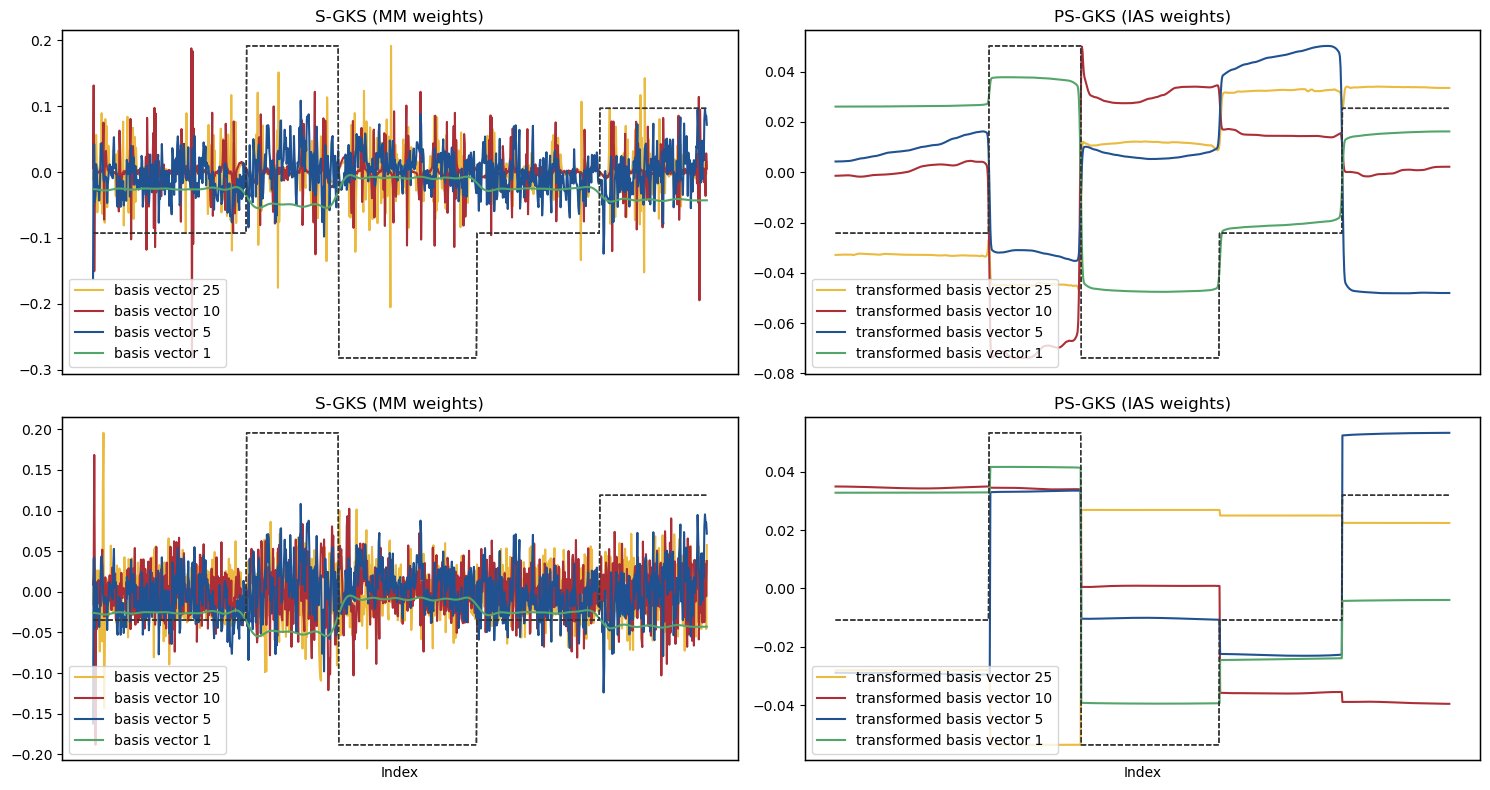

In [80]:
fig, axs = plt.subplots(2,2, figsize=(15,8))

loc = "lower left"
truth_lw = 1

kks = [0, 4, 9, 24]

for j, kk in enumerate(reversed(kks)):

    axs[0,0].plot(mm_data["V"][:,kk], label=f"basis vector {kk+1}", color=f"C{j+1}")
    axs[0,0].legend(loc=loc)
    axs[0,0].set_xticks([])
    axs[0,0].set_title("S-GKS (MM weights)")
    axst = axs[0,0].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])



for j, kk in enumerate(reversed(kks)):

    axs[0,1].plot(mm_pdata["Lopinv"] @ mm_pdata["V"][:,kk] / np.linalg.norm(mm_pdata["Lopinv"] @ mm_pdata["V"][:,kk]), label=f"transformed basis vector {kk+1}", color=f"C{j+1}")
    axs[0,1].legend(loc=loc)
    axs[0,1].set_xticks([])
    axs[0,1].set_title("PS-GKS (IAS weights)")
    axst = axs[0,1].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])



for j, kk in enumerate(reversed(kks)):

    axs[1,0].plot(ias_data["V"][:,kk], label=f"basis vector {kk+1}", color=f"C{j+1}")
    axs[1,0].legend(loc=loc)
    axs[1,0].set_xticks([])
    axs[1,0].set_xlabel("Index")
    axs[1,0].set_title("S-GKS (MM weights)")
    axst = axs[1,0].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])



for j, kk in enumerate(reversed(kks)):

    axs[1,1].plot(ias_pdata["Lopinv"] @ ias_pdata["V"][:,kk] / np.linalg.norm(ias_pdata["Lopinv"] @ ias_pdata["V"][:,kk]), label=f"transformed basis vector {kk+1}", color=f"C{j+1}")
    axs[1,1].legend(loc=loc)
    axs[1,1].set_xticks([])
    axs[1,1].set_title("PS-GKS (IAS weights)")
    axs[1,1].set_xlabel("Index")
    axst = axs[1,1].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    axst.set_yticks([])
    #axst.set_yticks([0, 2, 4, 6])


fig.tight_layout()
fig.savefig("1d_cosine_example_basis_vectors.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_example_basis_vectors.eps", format="eps", dpi=250, bbox_inches=None)

plt.show()

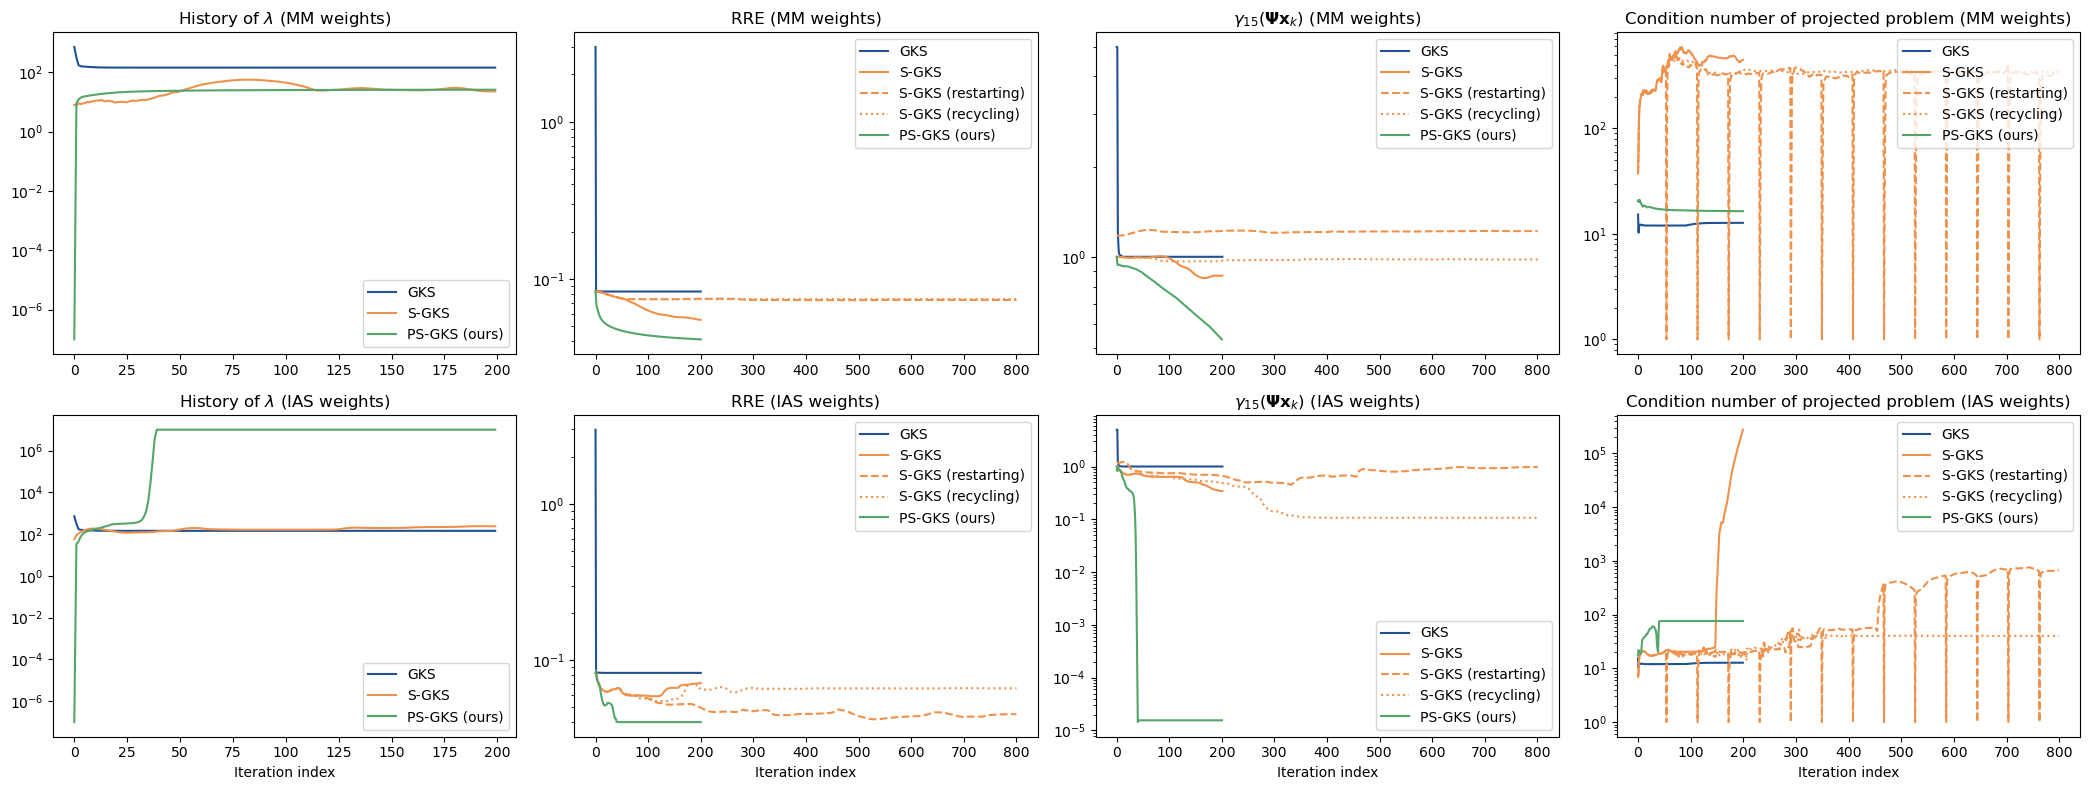

In [87]:
fig, axs = plt.subplots(2,4,figsize=(21,8))

loc="upper right"

# Lambda history

axs[0,0].semilogy([i for i in range(len(vdata["lambda_history"]))], vdata["lambda_history"], label="GKS", color="C3")
axs[0,0].plot([i for i in range(len(mm_data["lambda_history"]))], mm_data["lambda_history"], color="C5", label="S-GKS")
axs[0,0].plot([i for i in range(len(mm_pdata["lambda_history"]))], mm_pdata["lambda_history"], color="C4", label="PS-GKS (ours)")
axs[0,0].legend(loc="lower right")
axs[0,0].set_title("History of $\lambda$ (MM weights)")


axs[1,0].semilogy([i for i in range(len(vdata["lambda_history"]))], vdata["lambda_history"], label="GKS", color="C3")
axs[1,0].plot([i for i in range(len(ias_data["lambda_history"]))], ias_data["lambda_history"], color="C5", label="S-GKS")
axs[1,0].plot([i for i in range(len(ias_pdata["lambda_history"]))], ias_pdata["lambda_history"], color="C4", label="PS-GKS (ours)")
axs[1,0].legend(loc="lower right")
axs[1,0].set_xlabel("Iteration index")
axs[1,0].set_title("History of $\lambda$ (IAS weights)")

# RRE
axs[0,1].semilogy([i for i in range(len(vdata["rre_history"]))], vdata["rre_history"], label="GKS", color="C3")
axs[0,1].plot([i for i in range(len(mm_data["rre_history"]))], mm_data["rre_history"], color="C5", label="S-GKS")
axs[0,1].plot([i for i in range(len(mm_resdata["rre_history"]))], mm_resdata["rre_history"], color="C5", label="S-GKS (restarting)", ls="--")
axs[0,1].plot([i for i in range(len(mm_recdata["rre_history"]))], mm_recdata["rre_history"], color="C5", label="S-GKS (recycling)", ls=":")
axs[0,1].plot([i for i in range(len(mm_pdata["rre_history"]))], mm_pdata["rre_history"], color="C4", label="PS-GKS (ours)")
axs[0,1].set_title("RRE (MM weights)")
axs[0,1].legend(loc=loc)


axs[1,1].semilogy([i for i in range(len(vdata["rre_history"]))], vdata["rre_history"], label="GKS", color="C3")
axs[1,1].plot([i for i in range(len(ias_data["rre_history"]))], ias_data["rre_history"], color="C5", label="S-GKS")
axs[1,1].plot([i for i in range(len(ias_resdata["rre_history"]))], ias_resdata["rre_history"], color="C5", label="S-GKS (restarting)", ls="--")
axs[1,1].plot([i for i in range(len(ias_recdata["rre_history"]))], ias_recdata["rre_history"], color="C5", label="S-GKS (recycling)", ls=":")
axs[1,1].plot([i for i in range(len(ias_pdata["rre_history"]))], ias_pdata["rre_history"], color="C4", label="PS-GKS (ours)")
axs[1,1].set_title("RRE (IAS weights)")
axs[1,1].set_xlabel("Iteration index")
axs[1,1].legend(loc=loc)


# ksparsity
axs[0,2].semilogy([i for i in range(len(vdata["ksparsity_indices"]))], vdata["ksparsity_indices"], label="GKS", color="C3")
axs[0,2].plot([i for i in range(len(mm_data["ksparsity_indices"]))], mm_data["ksparsity_indices"], color="C5", label="S-GKS")
axs[0,2].plot([i for i in range(len(mm_resdata["ksparsity_indices"]))], mm_resdata["ksparsity_indices"], color="C5", label="S-GKS (restarting)", ls="--")
axs[0,2].plot([i for i in range(len(mm_recdata["ksparsity_indices"]))], mm_recdata["ksparsity_indices"], color="C5", label="S-GKS (recycling)", ls=":")
axs[0,2].plot([i for i in range(len(mm_pdata["ksparsity_indices"]))], mm_pdata["ksparsity_indices"], color="C4", label="PS-GKS (ours)")
axs[0,2].set_title("$\gamma_{15}(\\boldsymbol{\Psi} \mathbf{x}_{k})$ (MM weights)")
axs[0,2].legend(loc=loc)


axs[1,2].semilogy([i for i in range(len(vdata["ksparsity_indices"]))], vdata["ksparsity_indices"], label="GKS", color="C3")
axs[1,2].plot([i for i in range(len(ias_data["ksparsity_indices"]))], ias_data["ksparsity_indices"], color="C5", label="S-GKS")
axs[1,2].plot([i for i in range(len(ias_resdata["ksparsity_indices"]))], ias_resdata["ksparsity_indices"], color="C5", label="S-GKS (restarting)", ls="--")
axs[1,2].plot([i for i in range(len(ias_recdata["ksparsity_indices"]))], ias_recdata["ksparsity_indices"], color="C5", label="S-GKS (recycling)", ls=":")
axs[1,2].plot([i for i in range(len(ias_pdata["ksparsity_indices"]))], ias_pdata["ksparsity_indices"], color="C4", label="PS-GKS (ours)")
axs[1,2].set_title("$\gamma_{15}(\\boldsymbol{\Psi} \mathbf{x}_{k})$ (IAS weights)")
axs[1,2].set_xlabel("Iteration index")
axs[1,2].legend(loc="lower right")





# RRE
axs[0,3].semilogy([i for i in range(len(vdata["cond_ests"]))], vdata["cond_ests"], label="GKS", color="C3")
axs[0,3].plot([i for i in range(len(mm_data["cond_ests"]))], mm_data["cond_ests"], color="C5", label="S-GKS")
axs[0,3].plot([i for i in range(len(mm_resdata["cond_ests"]))], mm_resdata["cond_ests"], color="C5", label="S-GKS (restarting)", ls="--")
axs[0,3].plot([i for i in range(len(mm_recdata["cond_ests"]))], mm_recdata["cond_ests"], color="C5", label="S-GKS (recycling)", ls=":")
axs[0,3].plot([i for i in range(len(mm_pdata["cond_ests"]))], mm_pdata["cond_ests"], color="C4", label="PS-GKS (ours)")
axs[0,3].set_title("Condition number of projected problem (MM weights)")
axs[0,3].legend(loc=loc)


axs[1,3].semilogy([i for i in range(len(vdata["cond_ests"]))], vdata["cond_ests"], label="GKS", color="C3")
axs[1,3].plot([i for i in range(len(ias_data["cond_ests"]))], ias_data["cond_ests"], color="C5", label="S-GKS")
axs[1,3].plot([i for i in range(len(ias_resdata["cond_ests"]))], ias_resdata["cond_ests"], color="C5", label="S-GKS (restarting)", ls="--")
axs[1,3].plot([i for i in range(len(ias_recdata["cond_ests"]))], ias_recdata["cond_ests"], color="C5", label="S-GKS (recycling)", ls=":")
axs[1,3].plot([i for i in range(len(ias_pdata["cond_ests"]))], ias_pdata["cond_ests"], color="C4", label="PS-GKS (ours)")
axs[1,3].set_title("Condition number of projected problem (IAS weights)")
axs[1,3].set_xlabel("Iteration index")
axs[1,3].legend(loc=loc)



#["ksparsity_indices"]


# axs[0,0].plot([i for i in range(len(ias_data["w"]))], ias_pdata["V"][:,kk])
# axs[0,0].plot([i for i in range(len(mm_data["x"]))], ground_truth, label="Ground truth", color="C9", alpha=1.0)
# axs[0,0].plot([i for i in range(len(mm_data["x"]))], vdata["x"], label="GKS", color="C3")
# axs[0,0].plot([i for i in range(len(mm_data["x"]))], mm_data["x"], label="S-GKS", color="C5")
# axs[0,0].plot([i for i in range(len(mm_data["x"]))], mm_pdata["x"], label="PS-GKS", color="C4")


fig.tight_layout()
fig.savefig("1d_cosine_example_performance.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_example_performance.eps", format="eps", dpi=250, bbox_inches=None)
plt.show()

# Old plots

In [ ]:
fig, axs = plt.subplots(2,2, figsize=(15,8))

loc = "lower left"
truth_lw = 1

kks = [0, 4, 9, 24]

for j, kk in enumerate(reversed(kks)):

    axs[0,0].plot(mm_data["V"][:,kk], label=f"basis vector {kk+1}", color=f"C{j+1}")
    axs[0,0].legend(loc=loc)
    axs[0,0].set_xticks([])
    axs[0,0].set_title("S-GKS (MM weights)")
    axst = axs[0,0].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])



for j, kk in enumerate(reversed(kks)):

    axs[0,1].plot(mm_gkbdata["Lopinv"] @ mm_gkbdata["V"][:,kk] / np.linalg.norm(mm_pdata["Lopinv"] @ mm_pdata["V"][:,kk]), label=f"transformed basis vector {kk+1}", color=f"C{j+1}")
    axs[0,1].legend(loc=loc)
    axs[0,1].set_xticks([])
    axs[0,1].set_title("PS-GKS (IAS weights)")
    axst = axs[0,1].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])



for j, kk in enumerate(reversed(kks)):

    axs[1,0].plot(ias_data["V"][:,kk], label=f"basis vector {kk+1}", color=f"C{j+1}")
    axs[1,0].legend(loc=loc)
    axs[1,0].set_xticks([])
    axs[1,0].set_xlabel("Index")
    axs[1,0].set_title("S-GKS (MM weights)")
    axst = axs[1,0].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])



for j, kk in enumerate(reversed(kks)):

    axs[1,1].plot(ias_pdata["Lopinv"] @ ias_pdata["V"][:,kk] / np.linalg.norm(ias_pdata["Lopinv"] @ ias_pdata["V"][:,kk]), label=f"transformed basis vector {kk+1}", color=f"C{j+1}")
    axs[1,1].legend(loc=loc)
    axs[1,1].set_xticks([])
    axs[1,1].set_title("PS-GKS (IAS weights)")
    axs[1,1].set_xlabel("Index")
    axst = axs[1,1].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    axst.set_yticks([])
    #axst.set_yticks([0, 2, 4, 6])


fig.tight_layout()

plt.show()

In [ ]:
plt.plot(mmfkdata["x"], label="FGK", color="C9")
#plt.plot(mmfkdata["x"], label="FGK", color="C7")


In [22]:
plt.plot(mmfkdata["x"], label="FGK", color="C9")
#plt.plot(mmfkdata["x"], label="FGK", color="C7")


NameError: name 'mmfkdata' is not defined

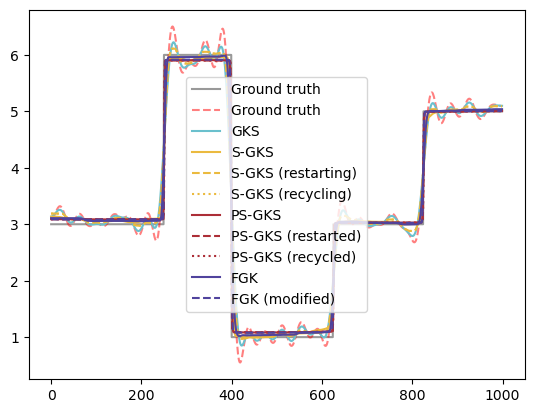

In [25]:
plt.plot(ground_truth, label="Ground truth", color="C9", alpha=0.5)
plt.plot(A.T @ b, label="Ground truth", color="red", alpha=0.5, ls="--")
plt.plot(vdata["x"], label="GKS", color="C0")
plt.plot(data["x"], label="S-GKS", color="C1")
plt.plot(resdata["x"], label="S-GKS (restarting)", color="C1", ls="--")
plt.plot(resdata["x"], label="S-GKS (recycling)", color="C1", ls=":")
plt.plot(pdata["x"], label="PS-GKS", color="C2")
plt.plot(respdata["x"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(recpdata["x"], label="PS-GKS (recycled)", color="C2", ls=":")
plt.plot(mmfkdata["x"], label="FGK", color="C7")
plt.plot(rmmfkdata["x"], label="FGK (modified)", color="C7", ls="--")
plt.legend()
plt.show()

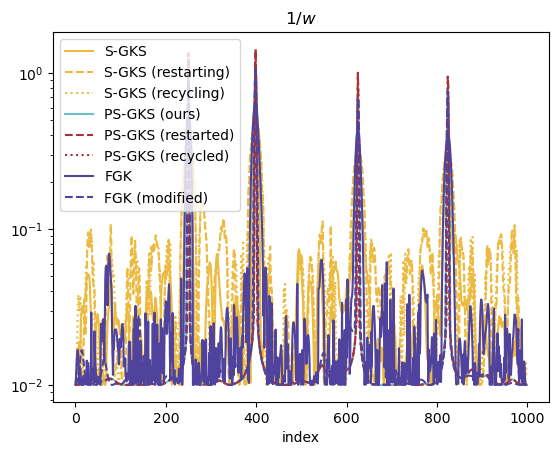

In [26]:
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
plt.semilogy(1.0/data['w'], label="S-GKS", color="C1")
plt.semilogy(1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--")
plt.semilogy(1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(1.0/pdata['w'], label="PS-GKS (ours)")
plt.plot(1.0/respdata["w"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(1.0/recpdata["w"], label="PS-GKS (recycled)", color="C2", ls=":")
plt.semilogy(1.0/mmfkdata["w"], label="FGK", color="C7")
plt.semilogy(1.0/rmmfkdata["w"], label="FGK (modified)", ls="--", color="C7")
plt.title("$1/w$")
plt.xlabel("index")
plt.legend()
plt.show()

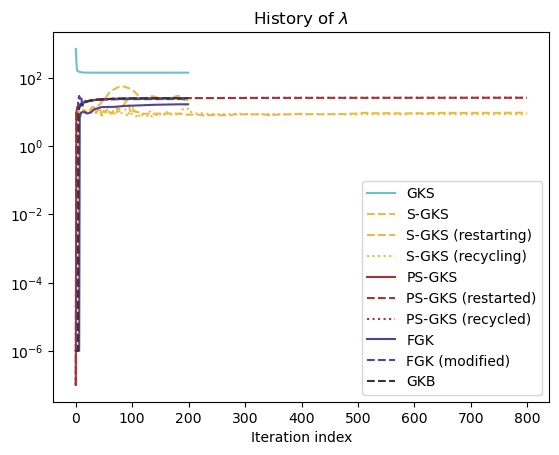

In [28]:
plt.semilogy(vdata["lambda_history"], label="GKS", color="C0")
plt.semilogy(data["lambda_history"], label="S-GKS", ls="--", alpha=1.0, color="C1")
plt.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C1")
plt.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C1")
plt.semilogy(pdata["lambda_history"], label="PS-GKS", alpha=1.0, color="C2")
plt.plot(respdata["lambda_history"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(recpdata["lambda_history"], label="PS-GKS (recycled)", color="C2", ls=":")
plt.semilogy(mmfkdata["lambda_history"], label="FGK", alpha=1.0, color="C7")
plt.semilogy(rmmfkdata["lambda_history"], label="FGK (modified)", ls="--", alpha=1.0, color="C7")
plt.semilogy(mmgkbdata["lambda_history"], label="GKB", ls="--", alpha=1.0, color="C9")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

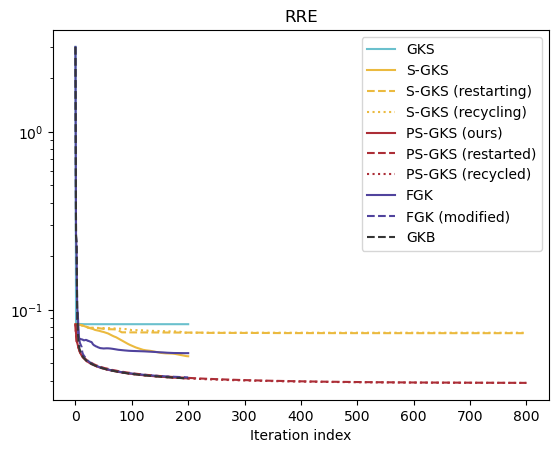

In [29]:
plt.semilogy(vdata["rre_history"], label="GKS", color="C0")
plt.semilogy(data["rre_history"], label="S-GKS", color="C1")
plt.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C1", ls="--")
plt.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(pdata["rre_history"], label="PS-GKS (ours)", color="C2")
plt.plot(respdata["rre_history"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(recpdata["rre_history"], label="PS-GKS (recycled)", color="C2", ls=":")
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.semilogy(mmfkdata["rre_history"], label="FGK", alpha=1.0, color="C7")
plt.semilogy(rmmfkdata["rre_history"], label="FGK (modified)", alpha=1.0, color="C7", ls="--")
plt.semilogy(mmgkbdata["rre_history"], label="GKB", ls="--", alpha=1.0, color="C9")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

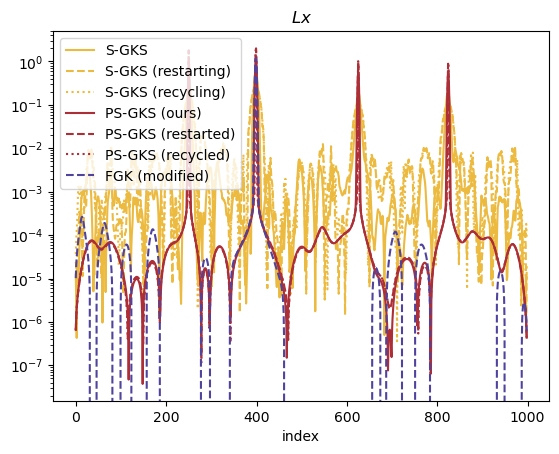

In [38]:
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
plt.semilogy(np.abs(L @ data['x']), label="S-GKS", color="C1")
plt.semilogy(np.abs(L @ resdata['x']), label="S-GKS (restarting)", color="C1", ls="--")
plt.semilogy(np.abs(L @ recdata['x']), label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(np.abs(L @ pdata['x']), label="PS-GKS (ours)", color="C2")
plt.plot(np.abs(L @ respdata["x"]), label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(np.abs(L @ recpdata["x"]), label="PS-GKS (recycled)", color="C2", ls=":")
#plt.semilogy(L @ mmfkdata["x"], label="FGK", color="C7")
plt.semilogy(L @ rmmfkdata["x"], label="FGK (modified)", color="C7", ls="--")

plt.title("$L x$")
plt.xlabel("index")
plt.legend()
plt.show()

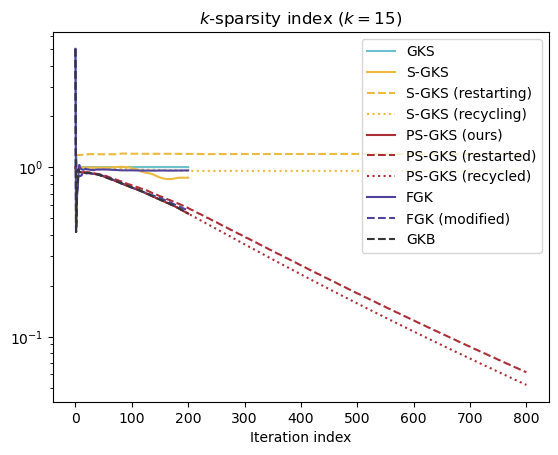

In [30]:
plt.semilogy(vdata["ksparsity_indices"], label="GKS", color="C0")
plt.semilogy(data["ksparsity_indices"], label="S-GKS", color="C1")
plt.semilogy(resdata["ksparsity_indices"], label="S-GKS (restarting)", color="C1", ls="--")
plt.semilogy(recdata["ksparsity_indices"], label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(pdata["ksparsity_indices"], label="PS-GKS (ours)", color="C2")
plt.plot(respdata["ksparsity_indices"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(recpdata["ksparsity_indices"], label="PS-GKS (recycled)", color="C2", ls=":")
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.semilogy(mmfkdata["ksparsity_indices"], label="FGK", alpha=1.0, color="C7")
plt.semilogy(rmmfkdata["ksparsity_indices"], label="FGK (modified)", alpha=1.0, color="C7", ls="--")
plt.semilogy(mmgkbdata["ksparsity_indices"], label="GKB", ls="--", alpha=1.0, color="C9")
plt.title("$k$-sparsity index ($k = 15$)")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

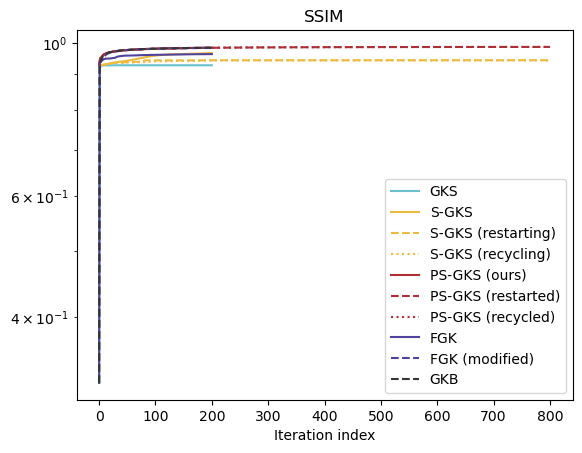

In [31]:
plt.plot(vdata["ssim_history"], label="GKS", color="C0")
plt.plot(data["ssim_history"], label="S-GKS", color="C1")
plt.plot(resdata["ssim_history"], label="S-GKS (restarting)", color="C1", ls="--")
plt.plot(recdata["ssim_history"], label="S-GKS (recycling)", color="C1", ls=":")
plt.plot(pdata["ssim_history"], label="PS-GKS (ours)", color="C2")
plt.plot(respdata["ssim_history"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(recpdata["ssim_history"], label="PS-GKS (recycled)", color="C2", ls=":")
plt.semilogy(mmfkdata["ssim_history"], label="FGK", alpha=1.0, color="C7")
plt.semilogy(rmmfkdata["ssim_history"], label="FGK (modified)", alpha=1.0, color="C7", ls="--")
plt.semilogy(mmgkbdata["ssim_history"], label="GKB", ls="--", alpha=1.0, color="C9")
plt.title("SSIM")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

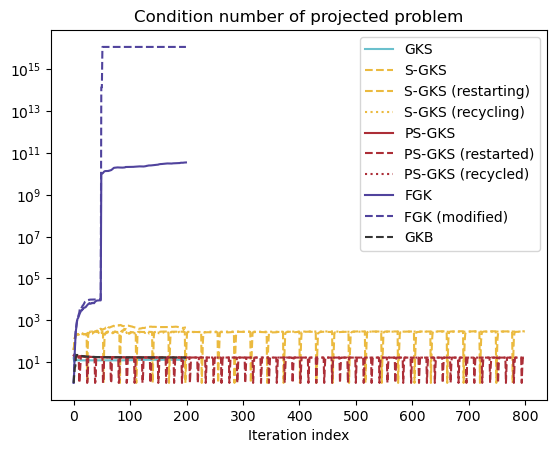

In [32]:
plt.semilogy(vdata["cond_ests"], label="GKS", color="C0")
plt.semilogy(data["cond_ests"], label="S-GKS", ls="--", alpha=1.0, color="C1")
plt.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C1")
plt.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C1")
plt.semilogy(pdata["cond_ests"], label="PS-GKS", alpha=1.0, color="C2")
plt.plot(respdata["cond_ests"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(recpdata["cond_ests"], label="PS-GKS (recycled)", color="C2", ls=":")
plt.plot(mmfkdata["cond_ests"], label="FGK", color="C7")
plt.plot(rmmfkdata["cond_ests"], label="FGK (modified)", color="C7", ls="--")
plt.semilogy(mmgkbdata["cond_ests"], label="GKB", ls="--", alpha=1.0, color="C9")
plt.title("Condition number of projected problem")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

# Plots in the paper

In [77]:
# # Create a figure with a 2x3 grid
# fig = plt.figure(figsize=(12, 8))
# gs = gridspec.GridSpec(3, 3, figure=fig)

# # Combine the first two subplots at positions (0,0) and (0,1)
# ax1 = fig.add_subplot(gs[0, :])
# ax1.plot([i for i in range(len(data["x"]))], ground_truth, label="Ground truth", color="C9", alpha=1.0)
# ax1.plot([i for i in range(len(data["x"]))], A.T @ b, label="$A^T b$", color="C2", alpha=1.0, ls="--")
# ax1.plot([i for i in range(len(data["x"]))], vdata["x"], label="GKS", color="C3")
# ax1.plot([i for i in range(len(data["x"]))], data["x"], label="S-GKS", color="C5")
# #ax1.plot(resdata["x"], label="S-GKS (restarting)", color="C3", ls="--")
# #ax1.plot(resdata["x"], label="S-GKS (recycling)", color="C3", ls=":")
# ax1.plot([i for i in range(len(data["x"]))], pdata["x"], label="PS-GKS (ours)", color="C4")

# inset_ax = ax1.inset_axes([0.5, 0.6, 0.25, 0.4])  # [left, bottom, width, height]
# inset_ax.set_xticks([])
# inset_ax.set_yticks([])
# inset_low_coord = 610
# inset_high_coord = 640
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], ground_truth[inset_low_coord:inset_high_coord], label="Ground truth", color="C9", alpha=1.0, marker="^")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], (A.T @ b)[inset_low_coord:inset_high_coord], label="$A^T b$", color="C2", alpha=1.0, marker=">")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], vdata["x"][inset_low_coord:inset_high_coord], label="GKS", color="C3", marker="s", facecolors="none")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], data["x"][inset_low_coord:inset_high_coord], label="S-GKS", color="C5", marker="x")
# #inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], resdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (restarting)", color="C3", ls="--")
# #inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], recdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (recycling)", color="C3", ls=":")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], pdata["x"][inset_low_coord:inset_high_coord], label="PS-GKS (ours)", color="C4", marker="o", facecolors="none")

# ax1.indicate_inset_zoom(inset_ax)
# ax1.legend(loc="lower right")
# ax1.set_xlabel("Index")
# ax1.set_title('Reconstructions')



# ax2 = fig.add_subplot(gs[1, :2])
# #plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/vdata['w'], label="GKS", color="C3", marker="s", s=8, facecolors="none")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C5", marker="x", s=8)
# #ax2.scatter([i for i in range(len(data["w"]))], 1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
# #ax2.scatter([i for i in range(len(data["w"]))], 1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS (ours)", color="C4", s=8, marker="o", facecolors="none")
# ax2.set_title("$1/w$")
# ax2.set_xlabel("Index")
# ax2.set_yscale("log")
# ax2.legend()

# ax4 = fig.add_subplot(gs[1, 2])
# ax4.set_title('Subplot (1,1)')
# ax4.semilogy(vdata["lambda_history"], label="GKS", color="C3")
# ax4.semilogy(data["lambda_history"], label="S-GKS", alpha=1.0, color="C5")
# ax4.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
# ax4.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
# ax4.semilogy(pdata["lambda_history"], label="PS-GKS", alpha=1.0, color="C4")
# ax4.set_title("History of $\\lambda$")
# ax4.set_xlabel("Iteration index")
# ax4.legend()



# # ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C1", marker="x", s=5)

# ax3 = fig.add_subplot(gs[2, 0])
# ax3.semilogy(vdata["rre_history"], label="GKS", color="C3")
# ax3.semilogy(data["rre_history"], label="S-GKS", color="C5")
# ax3.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C5", ls="--")
# ax3.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C5", ls=":")
# ax3.semilogy(pdata["rre_history"], label="PS-GKS (ours)", color="C4")
# #plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
# ax3.set_title("RRE")
# ax3.set_xlabel("Iteration index")
# ax3.legend()



# ax6 = fig.add_subplot(gs[2, 1])
# ax6.plot(vdata["ssim_history"], label="GKS", color="C3")
# ax6.plot(data["ssim_history"], label="S-GKS", color="C5")
# ax6.plot(resdata["ssim_history"], label="S-GKS (restarting)", color="C5", ls="--")
# ax6.plot(recdata["ssim_history"], label="S-GKS (recycling)", color="C5", ls=":")
# ax6.plot(pdata["ssim_history"], label="PS-GKS (ours)", color="C4")
# #plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
# ax6.set_title("SSIM")
# ax6.set_xlabel("Iteration index")
# ax6.legend()


# ax5 = fig.add_subplot(gs[2, 2])
# ax5.semilogy(vdata["cond_ests"], label="GKS", color="C3")
# ax5.semilogy(data["cond_ests"], label="S-GKS", alpha=1.0, color="C5")
# ax5.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
# ax5.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
# ax5.semilogy(pdata["cond_ests"], label="PS-GKS", alpha=1.0, color="C4")
# ax5.set_title("Condition number of projected problem")
# ax5.set_xlabel("Iteration index")
# ax5.legend(loc="lower right")


# # Adjust layout
# fig.tight_layout()
# #fig.savefig("1d_cosine_example_mm.png", dpi=250, bbox_inches=None)
# #fig.savefig("1d_cosine_example_mm.eps", format="eps", dpi=250, bbox_inches=None)
# plt.show()


In [78]:
# # Create a figure with a 2x3 grid
# fig = plt.figure(figsize=(12, 14))
# gs = gridspec.GridSpec(5, 3, figure=fig)

# # Combine the first two subplots at positions (0,0) and (0,1)
# ax1 = fig.add_subplot(gs[0, :])
# ax1.plot([i for i in range(len(data["x"]))], ground_truth, label="Ground truth", color="C9", alpha=1.0)
# ax1.plot([i for i in range(len(data["x"]))], A.T @ b, label="$A^T b$", color="C2", alpha=1.0, ls="--")
# ax1.plot([i for i in range(len(data["x"]))], vdata["x"], label="GKS", color="C3")
# ax1.plot([i for i in range(len(data["x"]))], data["x"], label="S-GKS", color="C5")
# #ax1.plot(resdata["x"], label="S-GKS (restarting)", color="C3", ls="--")
# #ax1.plot(resdata["x"], label="S-GKS (recycling)", color="C3", ls=":")
# ax1.plot([i for i in range(len(data["x"]))], pdata["x"], label="PS-GKS", color="C4")
# #ax1.plot([i for i in range(len(data["x"]))], respdata["x"], label="PS-GKS (restarting)", color="C4")
# #ax1.plot([i for i in range(len(data["x"]))], recpdata["x"], label="PS-GKS (recycling)", color="C4")
# ax1.plot([i for i in range(len(data["x"]))], mmfkdata["x"], label="FGK", color="C6")

# inset_ax = ax1.inset_axes([0.5, 0.6, 0.25, 0.4])  # [left, bottom, width, height]
# inset_ax.set_xticks([])
# inset_ax.set_yticks([])
# inset_low_coord = 610
# inset_high_coord = 640
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], ground_truth[inset_low_coord:inset_high_coord], label="Ground truth", color="C9", alpha=1.0, marker="^")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], (A.T @ b)[inset_low_coord:inset_high_coord], label="$A^T b$", color="C2", alpha=1.0, marker=">")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], vdata["x"][inset_low_coord:inset_high_coord], label="GKS", color="C3", marker="s", facecolors="none")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], data["x"][inset_low_coord:inset_high_coord], label="S-GKS", color="C5", marker="x")
# #inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], resdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (restarting)", color="C3", ls="--")
# #inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], recdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (recycling)", color="C3", ls=":")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], pdata["x"][inset_low_coord:inset_high_coord], label="PS-GKS", color="C4", marker="o", facecolors="none")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], mmfkdata["x"][inset_low_coord:inset_high_coord], label="FGK", color="C6", marker="<", facecolors="none")

# ax1.indicate_inset_zoom(inset_ax)
# ax1.legend(loc="lower right")
# ax1.set_xlabel("Index")
# ax1.set_title('Reconstructions')



# ax2 = fig.add_subplot(gs[1, :])
# #plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/vdata['w'], label="GKS", color="C3", marker="s", s=8, facecolors="none")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C5", marker="x", s=8)
# #ax2.scatter([i for i in range(len(data["w"]))], 1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
# #ax2.scatter([i for i in range(len(data["w"]))], 1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS", color="C4", s=8, marker="o", facecolors="none")
# #ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS (restarting)", color="C4", s=8, marker=">", facecolors="none")
# #ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS (recycling)", color="C4", s=8, marker="^", facecolors="none")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/mmfkdata['w'], label="FGK", color="C6", s=8, marker=">", facecolors="none")
# ax2.set_title("$1/w$")
# ax2.set_xlabel("Index")
# ax2.set_yscale("log")
# ax2.legend()


# # ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C1", marker="x", s=5)

# ax3 = fig.add_subplot(gs[2, :])
# ax3.semilogy(vdata["rre_history"], label="GKS", color="C3")
# ax3.semilogy(data["rre_history"], label="S-GKS", color="C5")
# ax3.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C5", ls="--")
# ax3.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C5", ls=":")
# ax3.semilogy(pdata["rre_history"], label="PS-GKS", color="C4")
# ax3.semilogy(resdata["rre_history"], label="PS-GKS (restarting)", color="C4", ls="--")
# ax3.semilogy(recdata["rre_history"], label="PS-GKS (recycling)", color="C4", ls=":")
# ax3.semilogy(mmfkdata["rre_history"], label="FGK", color="C6")
# ax3.semilogy(rmmfkdata["rre_history"], label="FGK (modified)", color="C6", ls="--")
# #plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
# #ax3.set_xscale("log")
# ax3.set_title("RRE")
# ax3.set_xlabel("Iteration index")
# ax3.legend(loc="upper right")




# ax4 = fig.add_subplot(gs[4, :2])
# ax4.set_title('Subplot (1,1)')
# ax4.semilogy(vdata["lambda_history"], label="GKS", color="C3")
# ax4.semilogy(data["lambda_history"], label="S-GKS", alpha=1.0, color="C5")
# ax4.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
# ax4.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
# ax4.semilogy(pdata["lambda_history"], label="PS-GKS", alpha=1.0, color="C4")
# ax4.semilogy(respdata["lambda_history"], label="PS-GKS (restarting)", alpha=1.0, color="C4", ls="--")
# ax4.semilogy(recpdata["lambda_history"], label="PS-GKS (recycling)", alpha=1.0, color="C4", ls=":")
# ax4.semilogy(mmfkdata["lambda_history"], label="FGK", alpha=1.0, color="C6")
# ax4.semilogy(rmmfkdata["lambda_history"], label="FGK (modified)", alpha=1.0, color="C6")
# ax4.set_title("History of $\\lambda$")
# ax4.set_xlabel("Iteration index")
# ax4.legend()





# ax6 = fig.add_subplot(gs[3, :])
# ax6.semilogy(vdata["ksparsity_indices"], label="GKS", color="C3")
# ax6.semilogy(data["ksparsity_indices"], label="S-GKS", color="C5")
# ax6.semilogy(resdata["ksparsity_indices"], label="S-GKS (restarting)", color="C5", ls="--")
# ax6.semilogy(recdata["ksparsity_indices"], label="S-GKS (recycling)", color="C5", ls=":")
# ax6.semilogy(pdata["ksparsity_indices"], label="PS-GKS", color="C4")
# ax6.semilogy(respdata["ksparsity_indices"], label="PS-GKS (restarting)", color="C4", ls="--")
# ax6.semilogy(respdata["ksparsity_indices"], label="PS-GKS (recycling)", color="C4", ls=":")
# ax6.semilogy(mmfkdata["ksparsity_indices"], label="FGK", color="C6")
# ax6.semilogy(rmmfkdata["ksparsity_indices"], label="FGK (modified)", color="C6", ls="--")
# #plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
# ax6.set_title("$s$-sparsity $\sigma_s$, $s = 15$")
# ax6.set_xlabel("Iteration index")
# ax6.legend()


# ax5 = fig.add_subplot(gs[4, 2])
# ax5.semilogy(vdata["cond_ests"], label="GKS", color="C3")
# ax5.semilogy(data["cond_ests"], label="S-GKS", alpha=1.0, color="C5")
# ax5.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
# ax5.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
# ax5.semilogy(pdata["cond_ests"], label="PS-GKS", alpha=1.0, color="C4")
# ax5.semilogy(respdata["cond_ests"], label="PS-GKS (restarting)", alpha=1.0, color="C4", ls="--")
# ax5.semilogy(recpdata["cond_ests"], label="PS-GKS (recycling)", alpha=1.0, color="C4", ls=":")
# ax5.semilogy(mmfkdata["cond_ests"], label="FGK", alpha=1.0, color="C6")
# ax5.semilogy(rmmfkdata["cond_ests"], label="FGK (modified)", alpha=1.0, color="C6", ls="--")
# ax5.set_title("Condition number of projected problem")
# ax5.set_xlabel("Iteration index")
# ax5.legend(loc="lower right")


# # Adjust layout
# fig.tight_layout()
# fig.savefig("1d_cosine_example_mm.png", dpi=250, bbox_inches=None)
# fig.savefig("1d_cosine_example_mm.eps", format="eps", dpi=250, bbox_inches=None)
# plt.show()


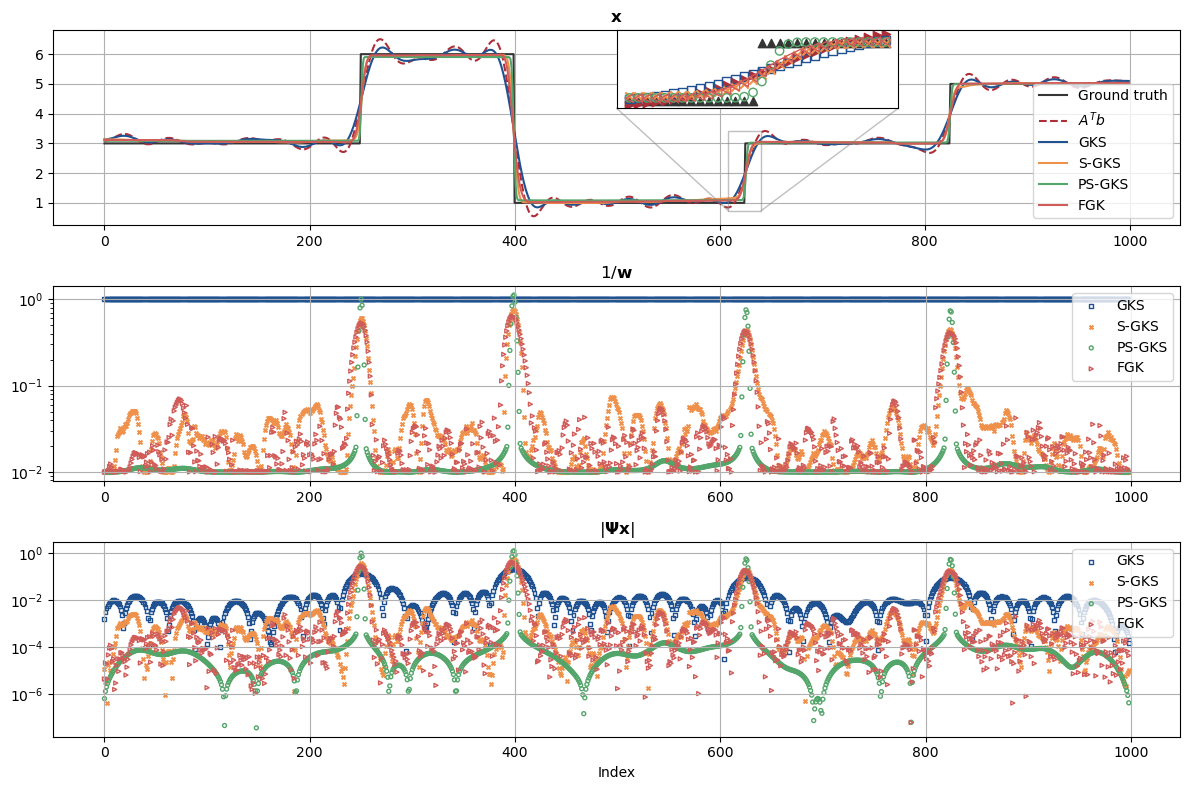

In [118]:
# Create a figure with a 2x3 grid
fig = plt.figure(figsize=(12, 8))
gs = gridspec.GridSpec(3, 1, figure=fig)

# Combine the first two subplots at positions (0,0) and (0,1)
ax1 = fig.add_subplot(gs[0])
ax1.plot([i for i in range(len(data["x"]))], ground_truth, label="Ground truth", color="C9", alpha=1.0)
ax1.plot([i for i in range(len(data["x"]))], A.T @ b, label="$A^T b$", color="C2", alpha=1.0, ls="--")
ax1.plot([i for i in range(len(data["x"]))], vdata["x"], label="GKS", color="C3")
ax1.plot([i for i in range(len(data["x"]))], data["x"], label="S-GKS", color="C5")
#ax1.plot(resdata["x"], label="S-GKS (restarting)", color="C3", ls="--")
#ax1.plot(resdata["x"], label="S-GKS (recycling)", color="C3", ls=":")
ax1.plot([i for i in range(len(data["x"]))], pdata["x"], label="PS-GKS", color="C4")
#ax1.plot([i for i in range(len(data["x"]))], respdata["x"], label="PS-GKS (restarting)", color="C4")
#ax1.plot([i for i in range(len(data["x"]))], recpdata["x"], label="PS-GKS (recycling)", color="C4")
ax1.plot([i for i in range(len(data["x"]))], mmfkdata["x"], label="FGK", color="C6")

inset_ax = ax1.inset_axes([0.5, 0.6, 0.25, 0.4])  # [left, bottom, width, height]
inset_ax.set_xticks([])
inset_ax.set_yticks([])
inset_low_coord = 610
inset_high_coord = 640
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], ground_truth[inset_low_coord:inset_high_coord], label="Ground truth", color="C9", alpha=1.0, marker="^")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], (A.T @ b)[inset_low_coord:inset_high_coord], label="$A^T b$", color="C2", alpha=1.0, marker=">")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], vdata["x"][inset_low_coord:inset_high_coord], label="GKS", color="C3", marker="s", facecolors="none")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], data["x"][inset_low_coord:inset_high_coord], label="S-GKS", color="C5", marker="x")
#inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], resdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (restarting)", color="C3", ls="--")
#inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], recdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (recycling)", color="C3", ls=":")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], pdata["x"][inset_low_coord:inset_high_coord], label="PS-GKS", color="C4", marker="o", facecolors="none")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], mmfkdata["x"][inset_low_coord:inset_high_coord], label="FGK", color="C6", marker="<", facecolors="none")
inset_ax.grid()

ax1.indicate_inset_zoom(inset_ax)
ax1.legend(loc="lower right")
#ax1.set_xlabel("Index")
ax1.set_title('$\\mathbf{x}$')
ax1.grid()


ax2 = fig.add_subplot(gs[1])
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/vdata['w'], label="GKS", color="C3", marker="s", s=8, facecolors="none")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C5", marker="x", s=8)
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS", color="C4", s=8, marker="o", facecolors="none")
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS (restarting)", color="C4", s=8, marker=">", facecolors="none")
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS (recycling)", color="C4", s=8, marker="^", facecolors="none")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/mmfkdata['w'], label="FGK", color="C6", s=8, marker=">", facecolors="none")
ax2.set_title("$1/\\mathbf{w}$")
#ax2.set_xlabel("Index")
ax2.set_yscale("log")
ax2.legend(loc="upper right")
ax2.grid()





ax10 = fig.add_subplot(gs[2])
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ vdata['x']), label="GKS", color="C3", marker="s", s=8, facecolors="none")
ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ data['x']), label="S-GKS", color="C5", marker="x", s=8)
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ resdata['x']), label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ recdata['x']), label="S-GKS (recycling)", color="C1", ls=":")
ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ pdata['x']), label="PS-GKS", color="C4", s=8, marker="o", facecolors="none")
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ pdata['x']), label="PS-GKS (restarting)", color="C4", s=8, marker=">", facecolors="none")
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ pdata['x']), label="PS-GKS (recycling)", color="C4", s=8, marker="^", facecolors="none")
ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ mmfkdata['x']), label="FGK", color="C6", s=8, marker=">", facecolors="none")
ax10.set_title("$| \\boldsymbol{\\Psi} \\mathbf{x} |$")
ax10.set_xlabel("Index")
ax10.set_yscale("log")
ax10.legend(loc="upper right")
ax10.grid()


# Adjust layout
fig.tight_layout()
fig.savefig("1d_cosine_example_mm_reconstructions.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_example_mm_reconstructions.eps", format="eps", dpi=250, bbox_inches=None)
plt.show()


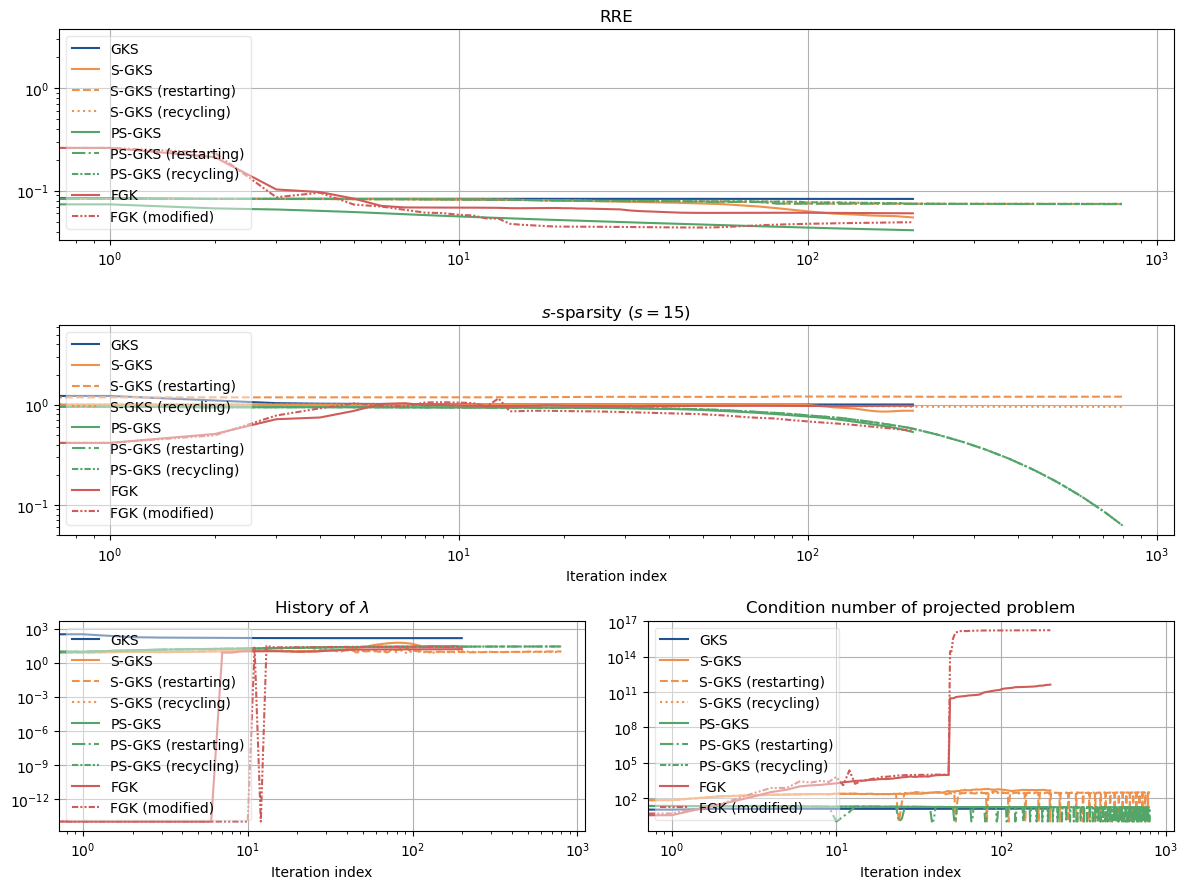

In [119]:
# Create a figure with a 2x3 grid
fig = plt.figure(figsize=(12, 9))
gs = gridspec.GridSpec(3, 2, figure=fig)


ax3 = fig.add_subplot(gs[0,:])
ax3.semilogy(vdata["rre_history"], label="GKS", color="C3")
ax3.semilogy(data["rre_history"], label="S-GKS", color="C5")
ax3.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax3.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax3.semilogy(pdata["rre_history"], label="PS-GKS", color="C4")
ax3.semilogy(resdata["rre_history"], label="PS-GKS (restarting)", color="C4", ls="dashdot")
ax3.semilogy(recdata["rre_history"], label="PS-GKS (recycling)", color="C4", ls=(0, (3, 1, 1, 1)))
ax3.semilogy(mmfkdata["rre_history"], label="FGK", color="C6")
ax3.semilogy(rmmfkdata["rre_history"], label="FGK (modified)", color="C6", ls=(0, (3, 1, 1, 1, 1, 1)))
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
#ax3.set_xscale("log")
ax3.set_title("RRE")
#ax3.set_xlabel("Iteration index")
ax3.set_xscale("log")
ax3.legend(loc="upper right")
ax3.legend().get_frame().set_alpha(0.45)
ax3.grid()



ax4 = fig.add_subplot(gs[2,0])
ax4.set_title('Subplot (1,1)')
ax4.semilogy(vdata["lambda_history"], label="GKS", color="C3")
ax4.semilogy(data["lambda_history"], label="S-GKS", alpha=1.0, color="C5")
ax4.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
ax4.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
ax4.semilogy(pdata["lambda_history"], label="PS-GKS", alpha=1.0, color="C4")
ax4.semilogy(respdata["lambda_history"], label="PS-GKS (restarting)", alpha=1.0, color="C4", ls="dashdot")
ax4.semilogy(recpdata["lambda_history"], label="PS-GKS (recycling)", alpha=1.0, color="C4", ls=(0, (3, 1, 1, 1)))
ax4.semilogy(mmfkdata["lambda_history"], label="FGK", alpha=1.0, color="C6")
ax4.semilogy(rmmfkdata["lambda_history"], label="FGK (modified)", alpha=1.0, color="C6", ls=(0, (3, 1, 1, 1, 1, 1)))
ax4.set_title("History of $\\lambda$")
ax4.set_xlabel("Iteration index")
ax4.legend(loc="upper left").get_frame().set_alpha(0.45)
ax4.set_xscale("log")
ax4.grid()
#ax4.legend().get_frame().set_alpha(0.45)



ax6 = fig.add_subplot(gs[1,:])
ax6.semilogy(vdata["ksparsity_indices"], label="GKS", color="C3")
ax6.semilogy(data["ksparsity_indices"], label="S-GKS", color="C5")
ax6.semilogy(resdata["ksparsity_indices"], label="S-GKS (restarting)", color="C5", ls="--")
ax6.semilogy(recdata["ksparsity_indices"], label="S-GKS (recycling)", color="C5", ls=":")
ax6.semilogy(pdata["ksparsity_indices"], label="PS-GKS", color="C4")
ax6.semilogy(respdata["ksparsity_indices"], label="PS-GKS (restarting)", color="C4", ls="dashdot")
ax6.semilogy(respdata["ksparsity_indices"], label="PS-GKS (recycling)", color="C4", ls=(0, (3, 1, 1, 1)))
ax6.semilogy(mmfkdata["ksparsity_indices"], label="FGK", color="C6")
ax6.semilogy(rmmfkdata["ksparsity_indices"], label="FGK (modified)", color="C6", ls=(0, (3, 1, 1, 1, 1, 1)))
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
ax6.set_title("$s$-sparsity ($s = 15$)")
ax6.set_xlabel("Iteration index")
#ax6.set_xlim(None, 10**3)
ax6.set_xscale("log")
ax6.legend(loc="upper right")
ax6.legend(loc="upper left").get_frame().set_alpha(0.45)
ax6.grid()


ax5 = fig.add_subplot(gs[2, 1])
ax5.semilogy(vdata["cond_ests"], label="GKS", color="C3")
ax5.semilogy(data["cond_ests"], label="S-GKS", alpha=1.0, color="C5")
ax5.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
ax5.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
ax5.semilogy(pdata["cond_ests"], label="PS-GKS", alpha=1.0, color="C4")
ax5.semilogy(respdata["cond_ests"], label="PS-GKS (restarting)", alpha=1.0, color="C4", ls="dashdot")
ax5.semilogy(recpdata["cond_ests"], label="PS-GKS (recycling)", alpha=1.0, color="C4", ls=(0, (3, 1, 1, 1)))
ax5.semilogy(mmfkdata["cond_ests"], label="FGK", alpha=1.0, color="C6")
ax5.semilogy(rmmfkdata["cond_ests"], label="FGK (modified)", alpha=1.0, color="C6", ls=(0, (3, 1, 1, 1, 1, 1)))
ax5.set_title("Condition number of projected problem")
ax5.set_xlabel("Iteration index")
ax5.set_xscale("log")
ax5.legend(loc="upper left").get_frame().set_alpha(0.45)
ax5.grid()


# Adjust layout
fig.tight_layout()
fig.savefig("1d_cosine_example_mm_performance.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_example_mm_performance.eps", format="eps", dpi=250, bbox_inches=None)
plt.show()


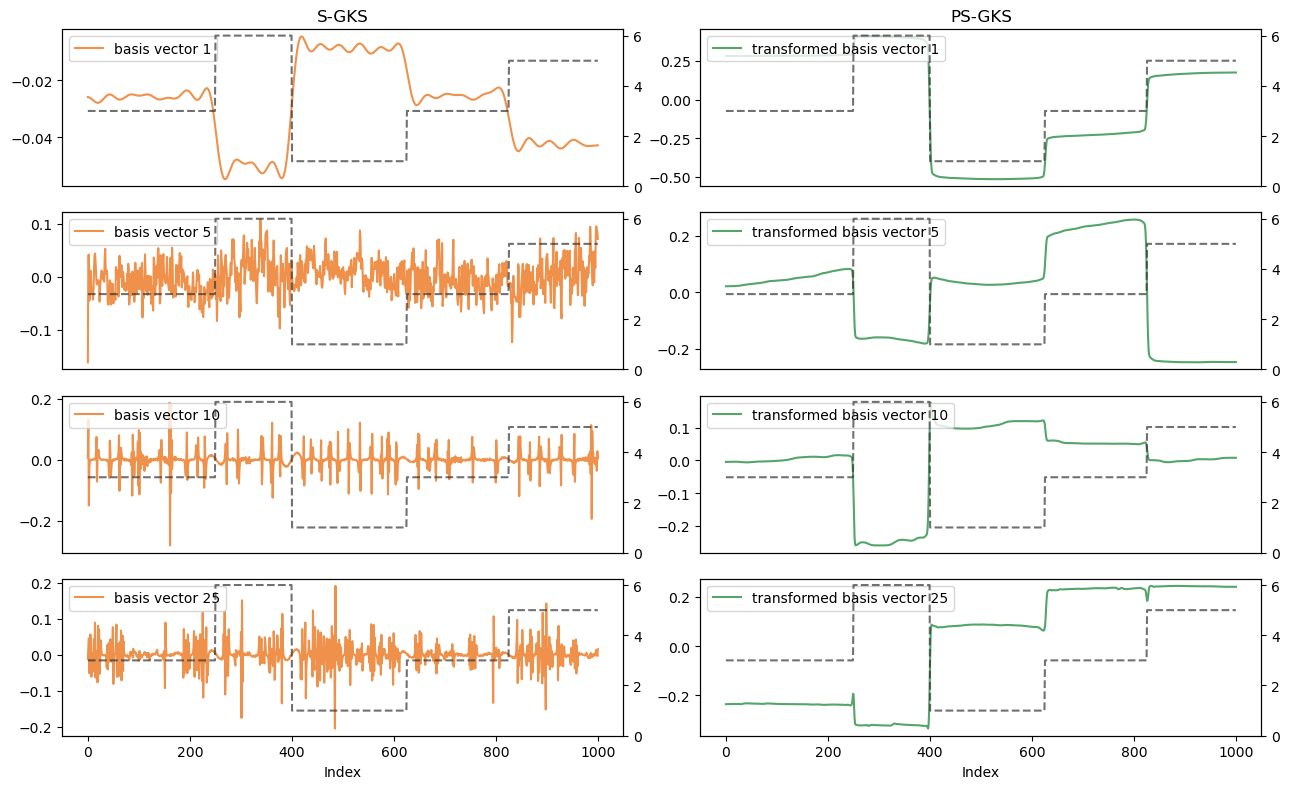

In [97]:
fig, axs = plt.subplots(4,2, figsize=(13,8))

loc = "upper left"

kk = 0
axs[0,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
axs[0,0].legend(loc=loc)
axs[0,0].set_xticks([])
axs[0,0].set_title("S-GKS")
axst = axs[0,0].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 4
axs[1,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
axs[1,0].legend(loc=loc)
axs[1,0].set_xticks([])
axst = axs[1,0].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 9
axs[2,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
axs[2,0].legend(loc=loc)
axs[2,0].set_xticks([])
axst = axs[2,0].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 24
axs[3,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
axs[3,0].legend(loc=loc)
axs[3,0].set_xlabel("Index")
axst = axs[3,0].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])




kk = 0
axs[0,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
axs[0,1].legend(loc=loc)
axs[0,1].set_xticks([])
axs[0,1].set_title("PS-GKS")
axst = axs[0,1].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 4
axs[1,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
axs[1,1].legend(loc=loc)
axs[1,1].set_xticks([])
axst = axs[1,1].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 9
axs[2,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
axs[2,1].legend(loc=loc)
axs[2,1].set_xticks([])
axst = axs[2,1].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 24
axs[3,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
axs[3,1].legend(loc=loc)
axs[3,1].set_xlabel("Index")
axst = axs[3,1].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

fig.tight_layout()
fig.savefig("1d_cosine_example_basis_vectors_mm.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_example_basis_vectors_mm.eps", format="eps", dpi=250, bbox_inches=None)

plt.show()

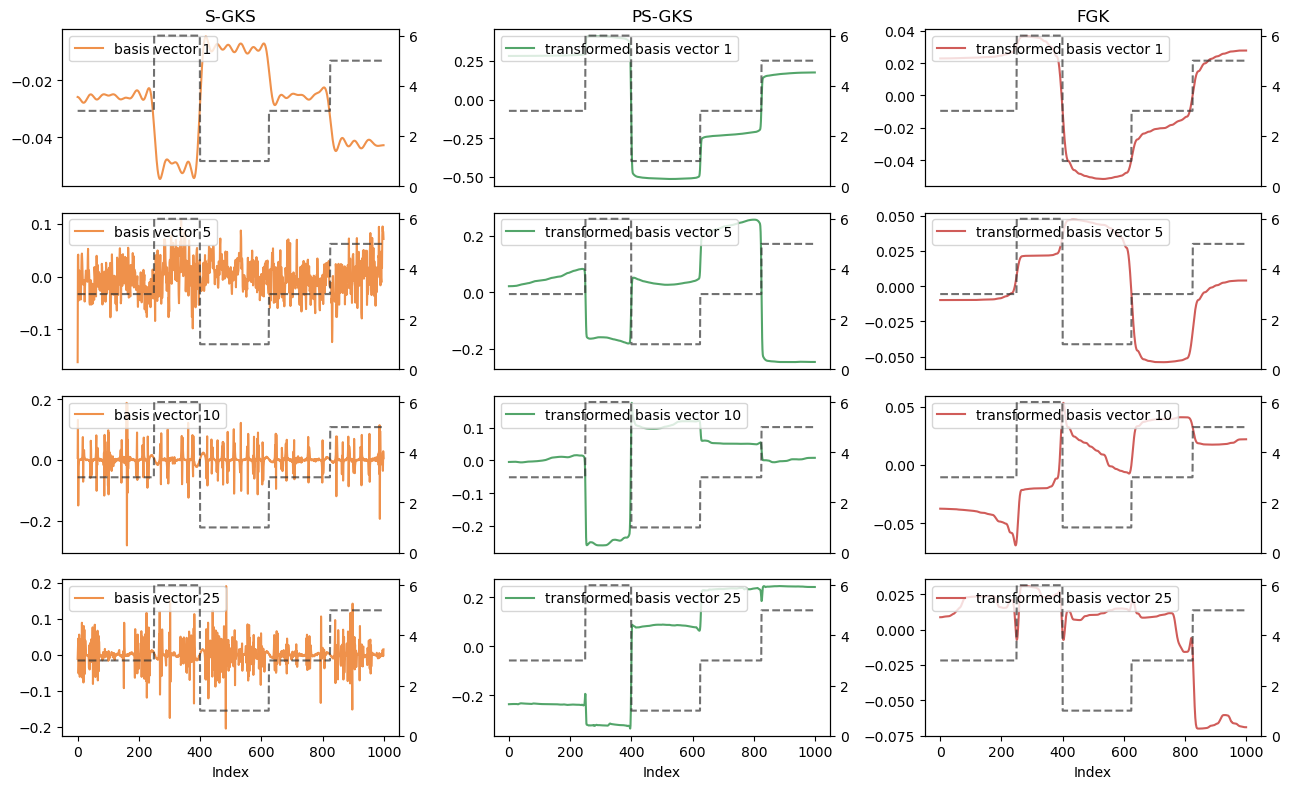

In [30]:
# fig, axs = plt.subplots(4,3, figsize=(13,8))

# loc = "upper left"

# kk = 0
# axs[0,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
# axs[0,0].legend(loc=loc)
# axs[0,0].set_xticks([])
# axs[0,0].set_title("S-GKS")
# axst = axs[0,0].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 4
# axs[1,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
# axs[1,0].legend(loc=loc)
# axs[1,0].set_xticks([])
# axst = axs[1,0].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 9
# axs[2,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
# axs[2,0].legend(loc=loc)
# axs[2,0].set_xticks([])
# axst = axs[2,0].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 24
# axs[3,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
# axs[3,0].legend(loc=loc)
# axs[3,0].set_xlabel("Index")
# axst = axs[3,0].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])




# kk = 0
# axs[0,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
# axs[0,1].legend(loc=loc)
# axs[0,1].set_xticks([])
# axs[0,1].set_title("PS-GKS")
# axst = axs[0,1].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 4
# axs[1,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
# axs[1,1].legend(loc=loc)
# axs[1,1].set_xticks([])
# axst = axs[1,1].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 9
# axs[2,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
# axs[2,1].legend(loc=loc)
# axs[2,1].set_xticks([])
# axst = axs[2,1].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 24
# axs[3,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
# axs[3,1].legend(loc=loc)
# axs[3,1].set_xlabel("Index")
# axst = axs[3,1].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])





# kk = 0
# axs[0,2].plot(mmfkdata["Z"][:,kk]/np.linalg.norm(mmfkdata["Z"][:,kk]), label=f"transformed basis vector {kk+1}", color="C6")
# axs[0,2].legend(loc=loc)
# axs[0,2].set_xticks([])
# axs[0,2].set_title("FGK")
# axst = axs[0,2].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 4
# axs[1,2].plot(mmfkdata["Z"][:,kk]/np.linalg.norm(mmfkdata["Z"][:,kk]), label=f"transformed basis vector {kk+1}", color="C6")
# axs[1,2].legend(loc=loc)
# axs[1,2].set_xticks([])
# axst = axs[1,2].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 9
# axs[2,2].plot(mmfkdata["Z"][:,kk]/np.linalg.norm(mmfkdata["Z"][:,kk]), label=f"transformed basis vector {kk+1}", color="C6")
# axs[2,2].legend(loc=loc)
# axs[2,2].set_xticks([])
# axst = axs[2,2].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 24
# axs[3,2].plot(mmfkdata["Z"][:,kk]/np.linalg.norm(mmfkdata["Z"][:,kk]), label=f"transformed basis vector {kk+1}", color="C6")
# axs[3,2].legend(loc=loc)
# axs[3,2].set_xlabel("Index")
# axst = axs[3,2].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])




# fig.tight_layout()
# #fig.savefig("1d_cosine_example_basis_vectors_mm.png", dpi=250, bbox_inches=None)
# #fig.savefig("1d_cosine_example_basis_vectors_mm.eps", format="eps", dpi=250, bbox_inches=None)

# plt.show()

In [27]:
mmfkdata.keys()

dict_keys(['x', 'V', 'U', 'H', 'Z', 'w', 'lambda_history', 'cond_ests', 'rre_history', 'ssim_history'])